# Classification Models: Prediksi Churn Nasabah Bank
**Applied Machine Learning**, Henri Ilham Caniago | 251321011 | 46A

**Tujuan:** memprediksi apakah nasabah bank akan keluar (`Exited = 1`) atau bertahan (`Exited = 0`) memakai data 10.000 nasabah dari Kaggle, lalu menampilkannya dengan **Streamlit**.

**Alur:** 1) Siapkan lingkungan → 2) Ambil data → 3) Kenali data → 4) Visualisasi → 5) Pra-pemrosesan → 6) Model dasar → 7) Bandingkan model → 8) Evaluasi data uji → 9) Data tidak seimbang → 10) Fitur penting → 11) Simpan model → 12) Tulis aplikasi → 13) Jalankan Streamlit

**Cara pakai:** menu **Runtime → Run all**. Tautan aplikasi muncul di sel Langkah 13.

## Langkah 1. Menyiapkan lingkungan
Colab sudah menyediakan pandas, scikit-learn, dan matplotlib. Yang perlu dipasang hanya Streamlit.

In [1]:
import sys
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    %pip install -q "streamlit>=1.50"

In [2]:
from pathlib import Path
import urllib.request, zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42

## Langkah 2. Mengambil data dari Kaggle
Dataset: [Churn Modelling (shrutimechlearn)](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling), file `Churn_Modelling.csv`.

Sel ini mengunduh langsung dari Kaggle. Jika gagal (misalnya Kaggle meminta login), unduh manual dari halaman tersebut lalu unggah saat diminta.

In [3]:
FILE_DATA = Path("data/Churn_Modelling.csv")
URL = "https://www.kaggle.com/api/v1/datasets/download/shrutimechlearn/churn-modelling"

if not FILE_DATA.exists():
    FILE_DATA.parent.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL, "data/dataset.zip")
        with zipfile.ZipFile("data/dataset.zip") as z:
            z.extract("Churn_Modelling.csv", "data")
    except Exception as galat:
        print("Unduhan otomatis gagal:", galat)
        if not IN_COLAB:
            raise
        from google.colab import files
        print("Silakan unggah Churn_Modelling.csv")
        unggahan = files.upload()
        FILE_DATA.write_bytes(unggahan["Churn_Modelling.csv"])

df = pd.read_csv(FILE_DATA)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Langkah 3. Mengenali data
Periksa tipe kolom, nilai kosong, data ganda, dan keseimbangan kelas.

In [4]:
df.info()
print("\nNilai kosong :", df.isna().sum().sum())
print("Baris ganda  :", df.duplicated().sum())
print("\nProporsi target:")
print(df["Exited"].value_counts(normalize=True))
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Nilai kosong : 0
Baris ganda  : 0

Proporsi target:
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: 

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


Data lengkap tanpa nilai kosong. Hanya sekitar **20%** nasabah yang keluar, jadi data **tidak seimbang**. Ini memengaruhi pilihan metrik.

## Langkah 4. Visualisasi (EDA)
Cari fitur yang tampak berhubungan dengan churn.

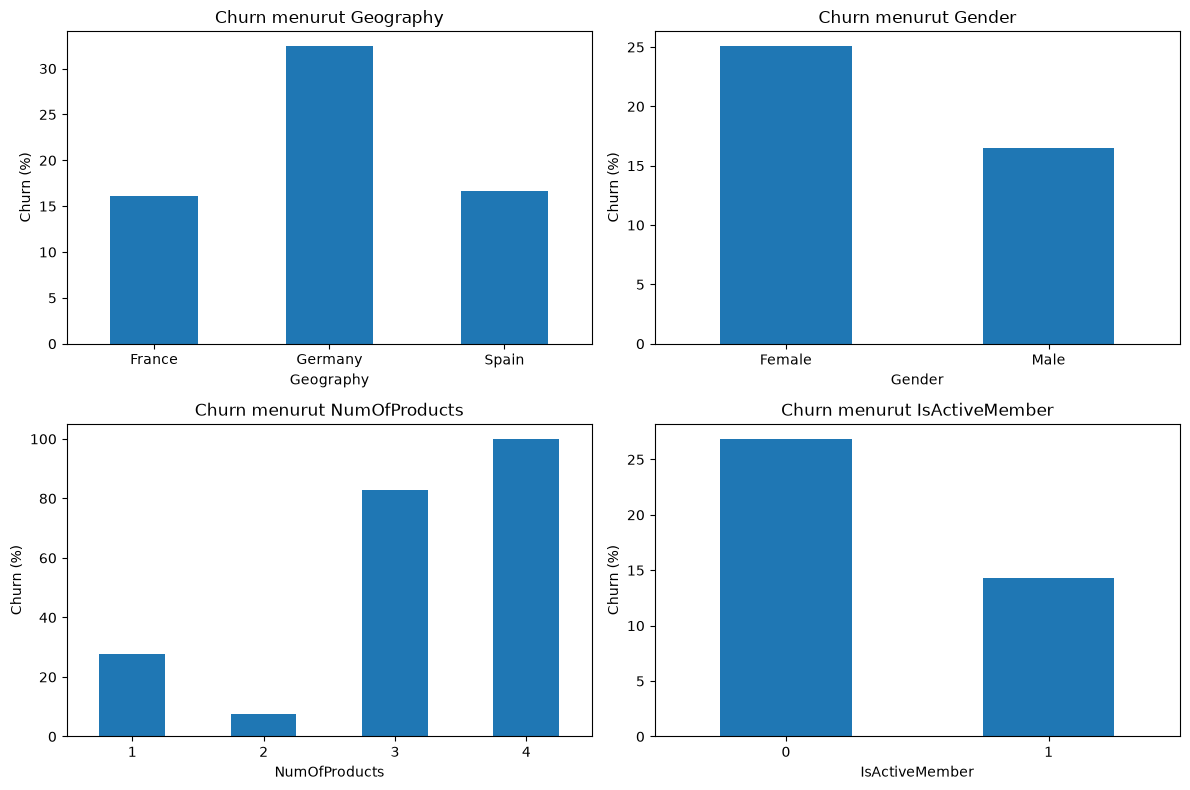

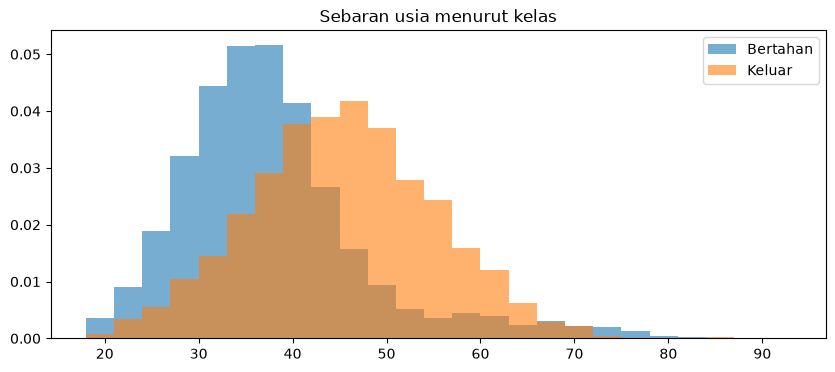

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, kolom in zip(ax.flat, ["Geography", "Gender", "NumOfProducts", "IsActiveMember"]):
    (df.groupby(kolom)["Exited"].mean() * 100).plot.bar(ax=a, rot=0)
    a.set_ylabel("Churn (%)")
    a.set_title(f"Churn menurut {kolom}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
tepi = np.arange(18, 95, 3)
for kelas, nama in [(0, "Bertahan"), (1, "Keluar")]:
    ax.hist(df.loc[df.Exited == kelas, "Age"], bins=tepi, alpha=0.6, density=True, label=nama)
ax.set_title("Sebaran usia menurut kelas")
ax.legend()
plt.show()

Terlihat churn lebih tinggi pada nasabah **Germany**, **perempuan**, **tidak aktif**, berusia lebih tua, serta pemilik **3-4 produk** (kelompok ini jumlahnya sedikit).

## Langkah 5. Pra-pemrosesan data
1. Buang `RowNumber`, `CustomerId`, `Surname` karena hanya identitas.
2. Bagi data 80% latih dan 20% uji secara **stratified** (proporsi kelas sama).
3. Fitur angka distandarkan (`StandardScaler`), fitur kategori diubah dengan **one-hot encoding**.
4. Semua digabung dalam `Pipeline`, sehingga skala hanya dipelajari dari data latih (tidak ada kebocoran data).

In [6]:
X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

fitur_kategori = ["Geography", "Gender"]
fitur_angka = [k for k in X.columns if k not in fitur_kategori]

praproses = ColumnTransformer([
    ("angka", StandardScaler(), fitur_angka),
    ("kategori", OneHotEncoder(drop="if_binary"), fitur_kategori),
])
print("Data latih:", X_train.shape, " Data uji:", X_test.shape)

Data latih: (8000, 10)  Data uji: (2000, 10)


## Langkah 6. Model dasar: Logistic Regression
Logistic regression menghitung probabilitas dengan fungsi sigmoid. Jika probabilitas ≥ 0,5, nasabah diprediksi keluar.

              precision    recall  f1-score   support

    Bertahan       0.82      0.97      0.89      1593
      Keluar       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



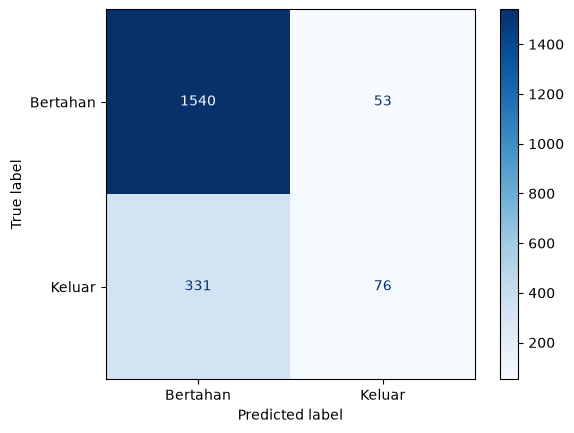

In [7]:
dasar = Pipeline([("pra", praproses), ("model", LogisticRegression(max_iter=1000))])
dasar.fit(X_train, y_train)
pred = dasar.predict(X_test)

print(classification_report(y_test, pred, target_names=["Bertahan", "Keluar"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Bertahan", "Keluar"], cmap="Blues")
plt.show()

Perhatikan: accuracy tampak lumayan, tetapi **recall kelas Keluar rendah**. Banyak nasabah yang akan keluar tidak terdeteksi.

## Langkah 7. Melatih dan membandingkan 8 model
Pemilihan model memakai **5-fold cross-validation pada data latih**. Data uji disimpan untuk penilaian akhir.
Metrik penentu: **ROC-AUC** (tidak bergantung pada ambang keputusan).

In [8]:
daftar_model = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=25),
    "Gaussian Naive Bayes": GaussianNB(),
    "Support Vector Machine": CalibratedClassifierCV(SVC(kernel="rbf"), cv=3, ensemble=False),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=3, random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models, hasil_cv, ambang_terbaik = {}, {}, {}

for nama, algoritma in daftar_model.items():
    pipa = Pipeline([("pra", praproses), ("model", algoritma)])
    # probabilitas "out-of-fold": tiap baris diprediksi oleh model yang tidak melihatnya
    p = cross_val_predict(pipa, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    skor = []
    for _, idx in cv.split(X_train, y_train):
        yv, pv = y_train.iloc[idx], p[idx]
        d = (pv >= 0.5).astype(int)
        skor.append({"Accuracy": accuracy_score(yv, d), "Precision": precision_score(yv, d, zero_division=0),
                     "Recall": recall_score(yv, d), "F1-Score": f1_score(yv, d), "ROC-AUC": roc_auc_score(yv, pv)})
    hasil_cv[nama] = pd.DataFrame(skor).mean()
    kandidat = np.arange(0.05, 0.96, 0.01)
    ambang_terbaik[nama] = float(max(kandidat, key=lambda t: f1_score(y_train, p >= t)))
    models[nama] = pipa.fit(X_train, y_train)
    print("Selesai:", nama)

tabel_cv = pd.DataFrame(hasil_cv).T.sort_values("ROC-AUC", ascending=False)
nama_terbaik = tabel_cv.index[0]
print("\nModel terbaik:", nama_terbaik)
tabel_cv.round(3)

Selesai: Logistic Regression


Selesai: Logistic Regression (balanced)


Selesai: k-Nearest Neighbors


Selesai: Gaussian Naive Bayes


Selesai: Support Vector Machine


Selesai: Decision Tree


Selesai: Random Forest


Selesai: Gradient Boosting

Model terbaik: Gradient Boosting


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Gradient Boosting,0.864,0.772,0.469,0.584,0.863
Random Forest,0.862,0.784,0.443,0.566,0.858
Decision Tree,0.859,0.776,0.433,0.555,0.838
k-Nearest Neighbors,0.838,0.766,0.297,0.428,0.831
Support Vector Machine,0.857,0.779,0.415,0.542,0.825
Gaussian Naive Bayes,0.815,0.572,0.372,0.450,0.782
Logistic Regression (balanced),0.708,0.380,0.685,0.488,0.766
Logistic Regression,0.810,0.597,0.214,0.315,0.763


## Langkah 8. Evaluasi pada data uji

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Gradient Boosting,0.870,0.789,0.496,0.609,0.869
Random Forest,0.866,0.806,0.450,0.577,0.860
Decision Tree,0.860,0.778,0.440,0.562,0.845
k-Nearest Neighbors,0.846,0.831,0.302,0.443,0.837
Support Vector Machine,0.862,0.801,0.425,0.555,0.825
Logistic Regression (balanced),0.714,0.387,0.700,0.499,0.777
Gaussian Naive Bayes,0.811,0.553,0.373,0.446,0.777
Logistic Regression,0.808,0.589,0.187,0.284,0.775


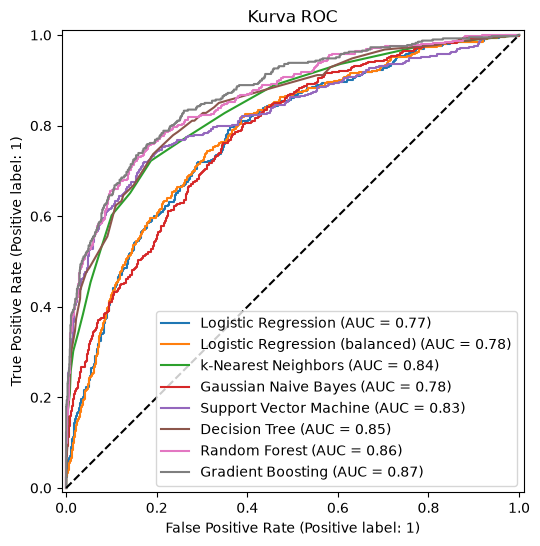

In [9]:
test_proba = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}

tabel_uji = pd.DataFrame({
    n: {"Accuracy": accuracy_score(y_test, p >= 0.5), "Precision": precision_score(y_test, p >= 0.5),
        "Recall": recall_score(y_test, p >= 0.5), "F1-Score": f1_score(y_test, p >= 0.5),
        "ROC-AUC": roc_auc_score(y_test, p)}
    for n, p in test_proba.items()}).T.sort_values("ROC-AUC", ascending=False)
display(tabel_uji.round(3))

fig, ax = plt.subplots(figsize=(9, 6))
for n, p in test_proba.items():
    RocCurveDisplay.from_predictions(y_test, p, name=n, ax=ax)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Kurva ROC")
plt.show()

## Langkah 9. Menangani data tidak seimbang
Dua cara tanpa membuat data tambahan: **class weight** dan **menggeser ambang keputusan**.

In [10]:
def ringkas(proba, ambang):
    d = proba >= ambang
    return {"Ambang": round(ambang, 2), "Precision": precision_score(y_test, d),
            "Recall": recall_score(y_test, d), "F1-Score": f1_score(y_test, d)}

t = ambang_terbaik[nama_terbaik]
pd.DataFrame({
    "Logistic Regression biasa": ringkas(test_proba["Logistic Regression"], 0.5),
    "Logistic Regression balanced": ringkas(test_proba["Logistic Regression (balanced)"], 0.5),
    f"{nama_terbaik}, ambang 0.50": ringkas(test_proba[nama_terbaik], 0.5),
    f"{nama_terbaik}, ambang disesuaikan": ringkas(test_proba[nama_terbaik], t),
}).T.round(3)

,Ambang,Precision,Recall,F1-Score
Logistic Regression biasa,0.50,0.589,0.187,0.284
Logistic Regression balanced,0.50,0.387,0.700,0.499
"Gradient Boosting, ambang 0.50",0.50,0.789,0.496,0.609
"Gradient Boosting, ambang disesuaikan",0.27,0.594,0.681,0.635


Menaikkan **recall** biasanya menurunkan **precision**. Untuk retensi nasabah, kehilangan nasabah (FN) umumnya lebih mahal daripada salah menawarkan promo (FP). Ambang disesuaikan dipilih dari data latih, bukan data uji.

## Langkah 10. Fitur yang paling berpengaruh
**Permutation importance**: acak nilai satu fitur, lalu ukur seberapa turun ROC-AUC.

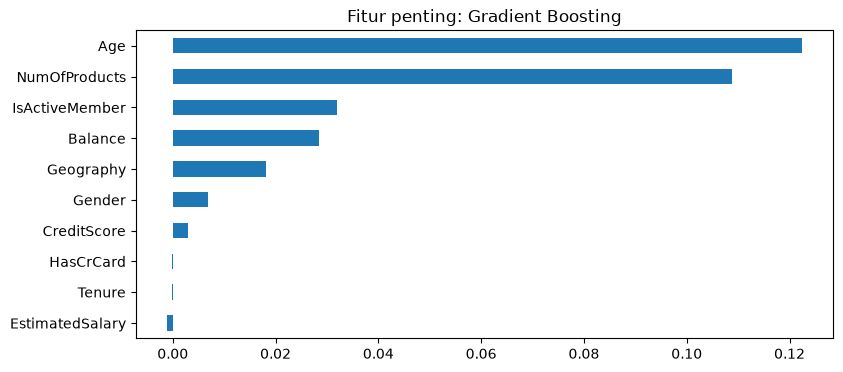

In [11]:
importance = {}
for nama, m in models.items():
    r = permutation_importance(m, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED)
    importance[nama] = pd.Series(r.importances_mean, index=X.columns)

importance[nama_terbaik].sort_values().plot.barh(figsize=(9, 4))
plt.title(f"Fitur penting: {nama_terbaik}")
plt.show()

## Langkah 11. Menyimpan model
Semua model dan hasil evaluasi disimpan ke `model_churn.joblib` agar aplikasi tidak perlu melatih ulang.

In [12]:
joblib.dump({
    "models": models, "best_name": nama_terbaik, "cv": tabel_cv,
    "test_proba": test_proba, "y_test": y_test.to_numpy(),
    "best_threshold": ambang_terbaik, "importance": importance,
    "features": list(X.columns), "sklearn_version": sklearn.__version__,
}, "model_churn.joblib", compress=3)

Path("requirements.txt").write_text(
    f"streamlit>=1.50\nscikit-learn=={sklearn.__version__}\npandas\nnumpy\nmatplotlib\njoblib\n")
print("Model tersimpan. Ukuran:", round(Path("model_churn.joblib").stat().st_size / 1e6, 1), "MB")

Model tersimpan. Ukuran: 4.8 MB


## Langkah 12. Menulis aplikasi Streamlit
Baris `%%writefile app.py` menyimpan seluruh isi sel menjadi file `app.py`. Aplikasi punya 6 menu: Beranda & Data, Eksplorasi Data, Perbandingan Model, Evaluasi Model, Prediksi Nasabah, dan Konsep Klasifikasi.

In [13]:
%%writefile app.py
"""Aplikasi Streamlit: Classification Models - Prediksi Churn Nasabah Bank.

Jalankan notebook Churn_Classification.ipynb lebih dulu, karena notebook itulah
yang membuat file model_churn.joblib yang dibaca aplikasi ini.
"""
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# Identitas (silakan sesuaikan)
NAMA = "Henri Ilham Caniago"
NIM = "251321011"
KELAS = "46A"

FOLDER = Path(__file__).parent
FILE_DATA = FOLDER / "data" / "Churn_Modelling.csv"
FILE_MODEL = FOLDER / "model_churn.joblib"
BIRU, MERAH = "#2563EB", "#DC2626"

st.set_page_config(page_title="Prediksi Churn Nasabah Bank", page_icon="🏦", layout="wide")


@st.cache_data
def muat_data():
    return pd.read_csv(FILE_DATA)


@st.cache_resource
def muat_model(waktu_ubah):
    # waktu_ubah membuat cache diperbarui bila model dilatih ulang
    return joblib.load(FILE_MODEL)


def tampilkan(fig):
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)


def hitung_metrik(y, proba, ambang):
    pred = (proba >= ambang).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1-Score": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, proba),
    }


for berkas in (FILE_DATA, FILE_MODEL):
    if not berkas.exists():
        st.error(f"File `{berkas.name}` belum ada. Jalankan dulu notebook Churn_Classification.ipynb.")
        st.stop()

df = muat_data()
paket = muat_model(FILE_MODEL.stat().st_mtime)
model_semua = paket["models"]
y_test = paket["y_test"]
nama_model = list(model_semua)

# ------------------------------------------------------------------ SIDEBAR
st.sidebar.title("🏦 Churn Nasabah Bank")
st.sidebar.info(f"**{NAMA}**\n\nNIM: {NIM}\n\nKelas: {KELAS}\n\nMata kuliah: Applied Machine Learning")
menu = st.sidebar.radio(
    "Menu",
    ["1. Beranda & Data", "2. Eksplorasi Data", "3. Perbandingan Model",
     "4. Evaluasi Model", "5. Prediksi Nasabah", "6. Konsep Klasifikasi"],
)
# Pilihan model hanya ditampilkan di menu yang hasilnya memang bergantung pada model.
# Baris session_state menjaga pilihan tetap tersimpan saat pindah menu.
st.session_state["pilih_model"] = st.session_state.get("pilih_model", paket["best_name"])
if menu.startswith(("4", "5")):
    st.sidebar.selectbox("Model yang dipakai", nama_model, key="pilih_model")
pilihan = st.session_state["pilih_model"]
st.sidebar.caption(f"Model terbaik menurut cross-validation: **{paket['best_name']}**")

# ------------------------------------------------------------------ 1. BERANDA
if menu.startswith("1"):
    st.title("Prediksi Churn Nasabah Bank")
    st.write(
        "Aplikasi **Classification Models** untuk memprediksi apakah seorang nasabah akan "
        "**keluar (churn)** atau **bertahan**. Ini klasifikasi **biner**: kelas 1 = keluar, kelas 0 = bertahan."
    )
    k1, k2, k3, k4 = st.columns(4)
    k1.metric("Jumlah nasabah", f"{len(df):,}")
    k2.metric("Nasabah keluar", f"{df.Exited.sum():,}")
    k3.metric("Tingkat churn", f"{df.Exited.mean():.1%}")
    k4.metric("Jumlah fitur model", len(paket["features"]))

    st.subheader("Contoh data")
    jumlah = st.slider("Jumlah baris yang ditampilkan", 5, 100, 10)
    st.dataframe(df.head(jumlah), width="stretch", hide_index=True)

    st.subheader("Kamus data")
    st.table(pd.DataFrame(
        [
            ("RowNumber, CustomerId, Surname", "Identitas nasabah (tidak dipakai model)"),
            ("CreditScore", "Skor kredit"),
            ("Geography", "Negara: France, Germany, Spain"),
            ("Gender", "Jenis kelamin"),
            ("Age", "Usia (tahun)"),
            ("Tenure", "Lama menjadi nasabah (tahun)"),
            ("Balance", "Saldo rekening"),
            ("NumOfProducts", "Jumlah produk bank yang dipakai"),
            ("HasCrCard", "Punya kartu kredit (1 = ya)"),
            ("IsActiveMember", "Nasabah aktif (1 = ya)"),
            ("EstimatedSalary", "Perkiraan gaji"),
            ("Exited", "TARGET: 1 = keluar, 0 = bertahan"),
        ],
        columns=["Kolom", "Arti"],
    ))
    st.caption("Sumber data: Kaggle, shrutimechlearn/churn-modelling (Churn_Modelling.csv).")

# ------------------------------------------------------------------ 2. EDA
elif menu.startswith("2"):
    st.title("Eksplorasi Data")
    kiri, kanan = st.columns(2)
    with kiri:
        st.subheader("Distribusi target")
        hitung = df.Exited.value_counts().sort_index()
        fig, ax = plt.subplots(figsize=(6, 4))
        batang = ax.bar(["Bertahan (0)", "Keluar (1)"], hitung.values, color=[BIRU, MERAH])
        ax.bar_label(batang)
        ax.set_ylabel("Jumlah nasabah")
        tampilkan(fig)
        st.caption("Data **tidak seimbang**: nasabah keluar jauh lebih sedikit, jadi accuracy saja bisa menyesatkan.")
    with kanan:
        st.subheader("Tingkat churn per kategori")
        label = {"Geography": "Negara", "Gender": "Jenis kelamin", "NumOfProducts": "Jumlah produk",
                 "IsActiveMember": "Nasabah aktif", "HasCrCard": "Punya kartu kredit", "Tenure": "Lama menjadi nasabah"}
        kolom = st.selectbox("Pilih kategori", list(label), format_func=label.get)
        ringkas = df.groupby(kolom)["Exited"].agg(["count", "mean"])
        fig, ax = plt.subplots(figsize=(6, 4))
        batang = ax.bar(ringkas.index.astype(str), ringkas["mean"] * 100, color=BIRU)
        ax.bar_label(batang, fmt="%.1f%%")
        ax.set_ylabel("Churn (%)")
        ax.set_xlabel(label[kolom])
        tampilkan(fig)
        st.dataframe(ringkas.rename(columns={"count": "Jumlah nasabah", "mean": "Proporsi churn"}), width="stretch")

    st.subheader("Sebaran fitur angka menurut kelas")
    angka = st.selectbox("Pilih fitur", ["Age", "CreditScore", "Balance", "EstimatedSalary"])
    fig, ax = plt.subplots(figsize=(11, 3.8))
    tepi = np.histogram_bin_edges(df[angka], bins=35)
    for kelas, warna, nama in [(0, BIRU, "Bertahan"), (1, MERAH, "Keluar")]:
        ax.hist(df.loc[df.Exited == kelas, angka], bins=tepi, alpha=0.55, color=warna, label=nama, density=True)
    ax.set_xlabel(angka)
    ax.set_ylabel("Kepadatan")
    ax.legend()
    tampilkan(fig)

    st.subheader("Korelasi antar fitur angka")
    korelasi = df.drop(columns=["RowNumber", "CustomerId"]).corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(9, 6))
    gambar = ax.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(korelasi)), korelasi.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(korelasi)), korelasi.columns)
    for i in range(len(korelasi)):
        for j in range(len(korelasi)):
            nilai = korelasi.iat[i, j]
            ax.text(j, i, f"{nilai:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(nilai) > 0.6 else "black")
    fig.colorbar(gambar)
    tampilkan(fig)

# ------------------------------------------------------------------ 3. PERBANDINGAN
elif menu.startswith("3"):
    st.title("Perbandingan Model Klasifikasi")
    st.subheader("Cross-validation 5-fold pada data latih (dasar pemilihan model)")
    st.dataframe(paket["cv"].style.format("{:.3f}").highlight_max(color="#BBF7D0"), width="stretch")
    st.success(f"Model dengan ROC-AUC cross-validation tertinggi: **{paket['best_name']}**")

    st.subheader(f"Hasil pada data uji ({len(y_test):,} nasabah, ambang 0,50)")
    uji = pd.DataFrame({n: hitung_metrik(y_test, paket["test_proba"][n], 0.5) for n in nama_model}).T
    st.dataframe(uji.style.format("{:.3f}").highlight_max(color="#BBF7D0"), width="stretch")

    metrik = st.selectbox("Grafik metrik data uji", list(uji.columns), index=list(uji.columns).index("ROC-AUC"))
    urut = uji[metrik].sort_values()
    fig, ax = plt.subplots(figsize=(10, 4.2))
    batang = ax.barh(urut.index, urut.values, color=BIRU)
    ax.bar_label(batang, fmt="%.3f", padding=3)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel(metrik)
    tampilkan(fig)

    st.subheader("Kurva ROC")
    fig, ax = plt.subplots(figsize=(8, 5.5))
    for n in nama_model:
        fpr, tpr, _ = roc_curve(y_test, paket["test_proba"][n])
        ax.plot(fpr, tpr, label=f"{n} ({uji.loc[n, 'ROC-AUC']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", label="Tebakan acak (0.500)")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate (Recall)")
    ax.legend(fontsize=8)
    tampilkan(fig)

# ------------------------------------------------------------------ 4. EVALUASI
elif menu.startswith("4"):
    st.title(f"Evaluasi: {pilihan}")
    proba = paket["test_proba"][pilihan]
    saran = paket["best_threshold"][pilihan]
    st.info(f"Ambang dengan F1 terbaik menurut data latih: **{saran:.2f}** (ambang bawaan 0,50).")
    ambang = st.slider("Ambang keputusan (probabilitas minimal untuk dianggap KELUAR)", 0.05, 0.95, 0.50, 0.01)

    m = hitung_metrik(y_test, proba, ambang)
    for kotak, (nama, nilai) in zip(st.columns(5), m.items()):
        kotak.metric(nama, f"{nilai:.3f}")
    tn, fp, fn, tp = confusion_matrix(y_test, (proba >= ambang).astype(int)).ravel()

    kiri, kanan = st.columns(2)
    with kiri:
        st.subheader("Confusion matrix")
        matriks = np.array([[tn, fp], [fn, tp]])
        fig, ax = plt.subplots(figsize=(5.5, 4.5))
        ax.imshow(matriks, cmap="Blues")
        for (i, j), nilai in np.ndenumerate(matriks):
            kode = [["TN", "FP"], ["FN", "TP"]][i][j]
            ax.text(j, i, f"{kode}\n{nilai}", ha="center", va="center", fontsize=14,
                    color="white" if nilai > matriks.max() / 2 else "black")
        ax.set_xticks([0, 1], ["Bertahan", "Keluar"])
        ax.set_yticks([0, 1], ["Bertahan", "Keluar"])
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Kenyataan")
        tampilkan(fig)
    with kanan:
        st.subheader("Kurva Precision-Recall")
        presisi, daya, _ = precision_recall_curve(y_test, proba)
        fig, ax = plt.subplots(figsize=(5.5, 4.5))
        ax.plot(daya, presisi, color=BIRU)
        ax.scatter([m["Recall"]], [m["Precision"]], color=MERAH, s=80, zorder=3, label=f"Ambang {ambang:.2f}")
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.legend()
        tampilkan(fig)

    st.markdown(
        f"Dari **{tp + fn}** nasabah yang benar-benar keluar, model menangkap **{tp}** dan meloloskan **{fn}**. "
        f"Dari **{tp + fp}** nasabah yang ditandai akan keluar, **{fp}** ternyata bertahan."
    )

    st.subheader("Fitur paling berpengaruh (permutation importance)")
    penting = paket["importance"][pilihan].sort_values()
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.barh(penting.index, penting.values, color=BIRU)
    ax.set_xlabel("Penurunan ROC-AUC bila nilai fitur diacak")
    tampilkan(fig)

# ------------------------------------------------------------------ 5. PREDIKSI
elif menu.startswith("5"):
    st.title("Prediksi Nasabah")
    st.write(f"Model yang dipakai: **{pilihan}**")
    model = model_semua[pilihan]
    ambang = st.slider("Ambang keputusan", 0.05, 0.95, 0.50, 0.01)
    satu, banyak = st.tabs(["Satu nasabah", "Banyak nasabah (CSV)"])

    with satu:
        with st.form("form_nasabah"):
            a, b, c = st.columns(3)
            masukan = {
                "CreditScore": a.number_input("Skor kredit", 300, 900, 650),
                "Geography": a.selectbox("Negara", sorted(df.Geography.unique())),
                "Gender": a.selectbox("Jenis kelamin", sorted(df.Gender.unique())),
                "Age": a.number_input("Usia", 18, 100, 40),
                "Tenure": b.slider("Lama menjadi nasabah (tahun)", 0, 10, 5),
                "Balance": b.number_input("Saldo", 0.0, 300000.0, 75000.0, 1000.0),
                "NumOfProducts": b.selectbox("Jumlah produk", [1, 2, 3, 4]),
                "HasCrCard": int(c.checkbox("Punya kartu kredit", True)),
                "IsActiveMember": int(c.checkbox("Nasabah aktif", True)),
                "EstimatedSalary": c.number_input("Perkiraan gaji", 0.0, 250000.0, 100000.0, 1000.0),
            }
            kirim = st.form_submit_button("Prediksi", type="primary")
        if kirim:
            p = model.predict_proba(pd.DataFrame([masukan])[paket["features"]])[0, 1]
            st.metric("Probabilitas keluar (churn)", f"{p:.1%}")
            st.progress(float(p))
            if p >= ambang:
                st.error("Prediksi: **KELUAR**. Nasabah ini layak diprioritaskan untuk program retensi.")
            else:
                st.success("Prediksi: **BERTAHAN**.")
            if masukan["NumOfProducts"] >= 3:
                jumlah = int((df.NumOfProducts >= 3).sum())
                st.warning(f"Hanya {jumlah} nasabah di data yang punya 3 produk atau lebih, hati-hati menafsirkan hasilnya.")

    with banyak:
        st.write("Unggah CSV yang memiliki kolom: " + ", ".join(f"`{k}`" for k in paket["features"]))
        contoh = df[paket["features"]].head(20)
        st.download_button("Unduh contoh CSV", contoh.to_csv(index=False), "contoh_nasabah.csv", "text/csv")
        unggah = st.file_uploader("File CSV", type="csv")
        if unggah is not None:
            try:
                baru = pd.read_csv(unggah)
                kurang = [k for k in paket["features"] if k not in baru.columns]
                if kurang:
                    st.error("Kolom yang belum ada: " + ", ".join(kurang))
                else:
                    p = model.predict_proba(baru[paket["features"]])[:, 1]
                    hasil = baru.assign(
                        Probabilitas_Churn=p.round(4),
                        Prediksi=np.where(p >= ambang, "Keluar", "Bertahan"),
                    ).sort_values("Probabilitas_Churn", ascending=False)
                    st.dataframe(hasil, width="stretch", hide_index=True)
                    st.download_button("Unduh hasil prediksi", hasil.to_csv(index=False), "hasil_prediksi.csv", "text/csv")
            except ValueError as galat:
                st.error(f"CSV tidak bisa diproses (periksa nilai kosong atau kategori yang tidak dikenal): {galat}")

# ------------------------------------------------------------------ 6. KONSEP
else:
    st.title("Konsep Classification Models")
    st.markdown(
        """
**Klasifikasi** adalah supervised learning yang memprediksi **kategori**. Bandingkan dengan regresi yang memprediksi angka.

| Jenis | Contoh |
|---|---|
| Biner (2 kelas) | Nasabah keluar atau bertahan (**aplikasi ini**) |
| Multikelas | Mengenali angka tulisan tangan 0-9 |
| Multilabel | Satu artikel diberi beberapa topik sekaligus |

### Logistic Regression
Walaupun namanya "regression", ini algoritma klasifikasi. Fungsi **sigmoid** mengubah skor menjadi probabilitas 0 sampai 1:
"""
    )
    st.latex(r"P(y=1\mid x)=\frac{1}{1+e^{-(b_0+b_1x_1+\dots+b_nx_n)}}")
    z = np.linspace(-8, 8, 200)
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(z, 1 / (1 + np.exp(-z)), color=BIRU)
    ax.axhline(0.5, color=MERAH, linestyle="--", label="Ambang 0,5")
    ax.set_xlabel("Skor linear")
    ax.set_ylabel("Probabilitas")
    ax.legend()
    tampilkan(fig)

    st.markdown(
        """
### Algoritma lain yang dibandingkan
| Algoritma | Ide dasar |
|---|---|
| k-Nearest Neighbors | Suara terbanyak dari k nasabah yang paling mirip |
| Gaussian Naive Bayes | Teorema Bayes dengan anggapan fitur saling bebas |
| Support Vector Machine | Mencari batas pemisah dengan margin terlebar |
| Decision Tree | Rangkaian pertanyaan ya/tidak |
| Random Forest | Gabungan banyak pohon yang dibuat dari sampel acak |
| Gradient Boosting | Pohon dibuat berurutan untuk memperbaiki kesalahan sebelumnya |

### Mengukur kinerja
- **TP**: keluar dan diprediksi keluar. **TN**: bertahan dan diprediksi bertahan.
- **FP**: bertahan tetapi diprediksi keluar. **FN**: keluar tetapi diprediksi bertahan.
"""
    )
    st.latex(r"Accuracy=\frac{TP+TN}{TP+TN+FP+FN}\qquad Precision=\frac{TP}{TP+FP}")
    st.latex(r"Recall=\frac{TP}{TP+FN}\qquad F1=2\times\frac{Precision\times Recall}{Precision+Recall}")
    st.markdown(
        f"""
- **ROC-AUC**: kemampuan model memberi skor lebih tinggi pada nasabah yang keluar (0,5 = acak, 1 = sempurna).

### Data tidak seimbang
Hanya {df.Exited.mean():.1%} nasabah yang keluar. Model yang selalu menjawab "bertahan" sudah mendapat accuracy
{1 - df.Exited.mean():.1%}, padahal tidak menemukan satu pun nasabah yang akan keluar.
Cara menanganinya: **class weight**, **oversampling/undersampling**, atau **menggeser ambang keputusan**.
"""
    )

Overwriting app.py


## Langkah 13. Menjalankan aplikasi
Colab tidak bisa membuka `localhost` secara langsung, jadi dipakai **Cloudflare Quick Tunnel** (gratis, tanpa akun).

⚠️ Tautan yang muncul bersifat **publik**: siapa pun yang punya tautannya bisa membuka aplikasi. Tautan mati saat runtime Colab berhenti.

In [14]:
import re, subprocess, time

def tunggu(cek, detik=60):
    for _ in range(detik):
        hasil = cek()
        if hasil:
            return hasil
        time.sleep(1)

def streamlit_siap():
    try:
        return urllib.request.urlopen("http://localhost:8501/_stcore/health").read() == b"ok"
    except OSError:
        return False

if IN_COLAB:
    !pkill -f "streamlit run" ; pkill -f "cloudflared tunnel"
    if not Path("cloudflared").exists():
        !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
        !chmod +x cloudflared

    subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py", "--server.headless", "true",
                      "--server.port", "8501"], stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
    assert tunggu(streamlit_siap), "Streamlit gagal jalan, lihat streamlit.log"

    subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                     stdout=open("tunnel.log", "w"), stderr=subprocess.STDOUT)
    alamat = tunggu(lambda: re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", Path("tunnel.log").read_text()))
    print("Buka aplikasi di:", alamat.group(0) if alamat else "tautan belum muncul, lihat tunnel.log")
else:
    print("Bukan di Colab. Jalankan di terminal:  streamlit run app.py")

## Kesimpulan
- Model berbasis pohon (ensemble) menangkap pola non-linear lebih baik daripada logistic regression.
- Karena data tidak seimbang, **accuracy tidak cukup**: lihat precision, recall, F1, confusion matrix, dan ROC-AUC.
- Class weight atau penyesuaian ambang menaikkan recall dengan mengorbankan precision.
- Lihat grafik Langkah 10 untuk fitur yang paling menentukan churn.